In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(str(Path().resolve().parent / "src"))

from model_sampler import DDIMSampler
from results import ModelResults, ModelComparison, build_dataset, METRICS_PRED, METRICS_PLAN, METRICS_PLAN_EXTENDED, is_higher_better, get_metric_abbr, get_metric_label

In [3]:
dataset = build_dataset('test')

In [4]:
unet_baseline = ModelResults('107-deeplabv3plus', 'unet', 199, 'test', dataset)
baseline = ModelResults('112-beamdiff-bf16', 'ddpm-1000', 199, 'test', dataset)

In [5]:
ws_unet = ModelResults('132-warmstart-deeplabv3plus', 'warm-start-unet', 199, 'test', dataset)
wsd = ModelResults('133-wsd', 'ddpm-1000', 199, 'test', dataset)

FileNotFoundError: [Errno 2] No such file or directory: '/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/samples/133-wsd/ddpm-1000/test_199/_sample_metrics.csv'

In [8]:
comparison = ModelComparison(
  [unet_baseline, baseline, ws_unet],
  ['U-Net Baseline', 'Diffusion Baseline', 'Warm-Start U-Net']
)

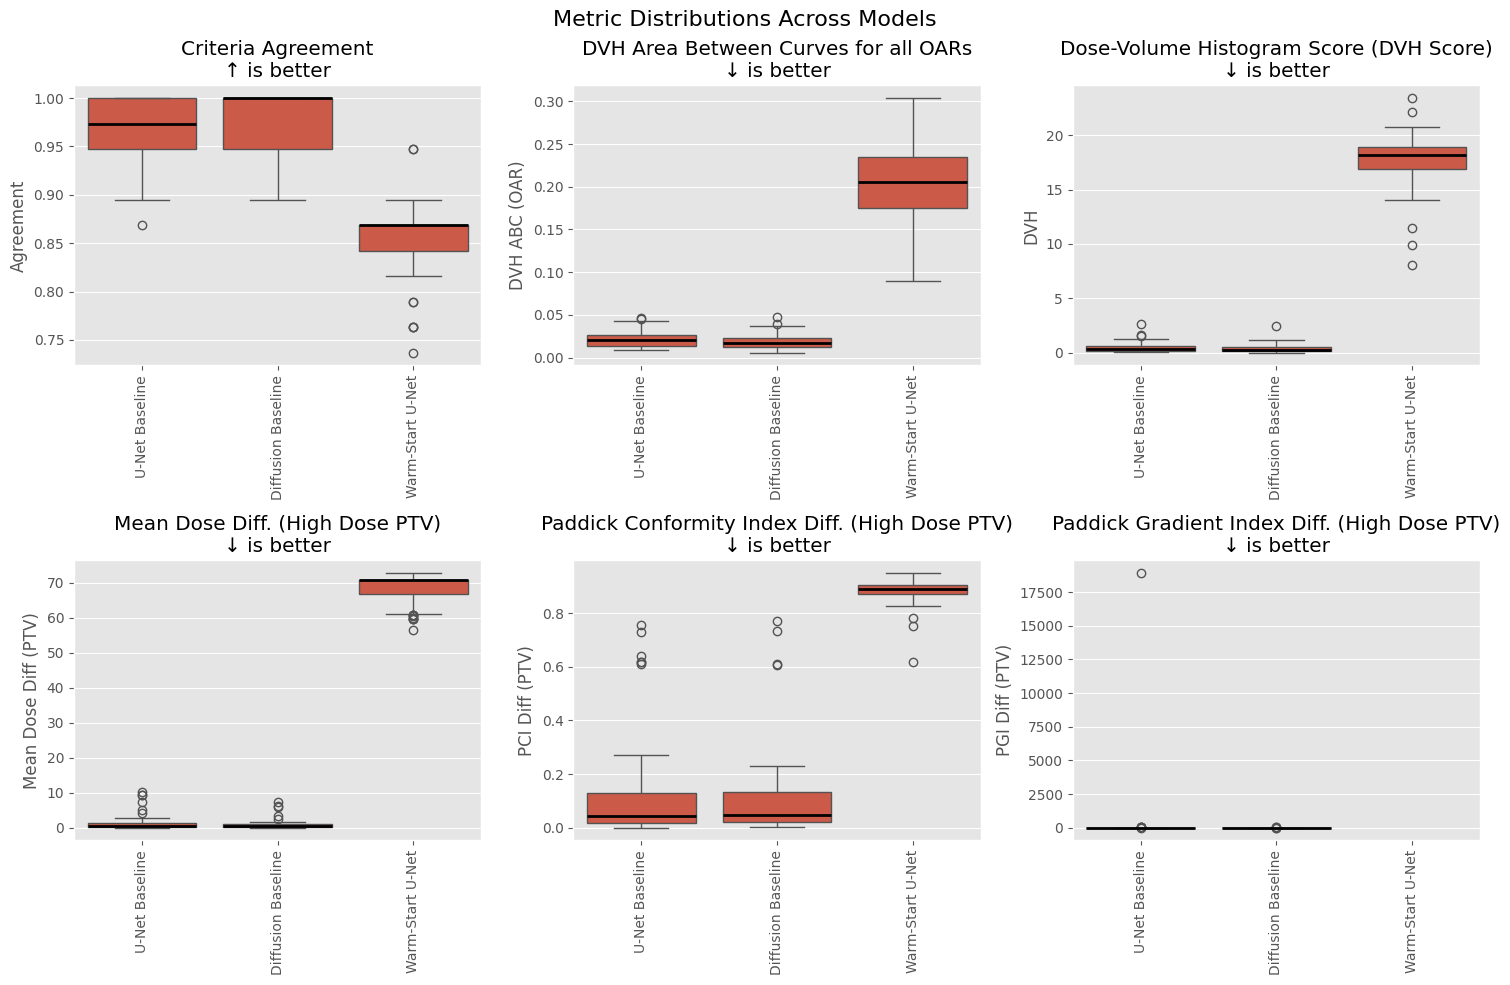

In [10]:
_ = comparison.plot_metric_distributions(METRICS_PRED)